In [18]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder,LabelEncoder
from sklearn.impute import SimpleImputer


In [2]:
df = pd.read_csv('laptopData.csv')
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [3]:
df.drop("Unnamed: 0" , inplace = True , axis = 1)

In [4]:
df.describe()

,Price
count,1273.000000
mean,59955.814073
std,37332.251005
min,9270.720000
25%,31914.720000
50%,52161.120000
75%,79333.387200
max,324954.720000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1273 non-null   object 
 1   TypeName          1273 non-null   object 
 2   Inches            1273 non-null   object 
 3   ScreenResolution  1273 non-null   object 
 4   Cpu               1273 non-null   object 
 5   Ram               1273 non-null   object 
 6   Memory            1273 non-null   object 
 7   Gpu               1273 non-null   object 
 8   OpSys             1273 non-null   object 
 9   Weight            1273 non-null   object 
 10  Price             1273 non-null   float64
dtypes: float64(1), object(10)
memory usage: 112.1+ KB


In [6]:
df["Weight"] = df["Weight"].replace("?", np.nan, regex = False)

In [7]:
df.isna().sum()

,0
Company,30
TypeName,30
Inches,30
ScreenResolution,30
Cpu,30
Ram,30
Memory,30
Gpu,30
OpSys,30
Weight,31


In [8]:
for col in df.columns :
    df.dropna(subset = col , inplace = True)
df.isna().sum()

,0
Company,0
TypeName,0
Inches,0
ScreenResolution,0
Cpu,0
Ram,0
Memory,0
Gpu,0
OpSys,0
Weight,0


In [9]:
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [10]:
df[df["Weight"] == "?"]


,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price


In [11]:
df["Weight"] = df["Weight"].str.replace("kg", "" , regex = False)
df["Weight"] = df["Weight"].str.replace("Kg", "", regex = False).str.strip().astype(float)

In [12]:
df["Ram"] = df["Ram"].str.replace("GB", "").str.strip().astype(float)

In [13]:
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8.0,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8.0,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8.0,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16.0,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8.0,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080


In [14]:
X = df.drop('Price', axis=1)
y = df['Price']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
label = df.select_dtypes("object").columns
label

Index(['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Memory',
       'Gpu', 'OpSys'],
      dtype='object')

In [24]:
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

X_train[label] = encoder.fit_transform(X_train[label])
X_test[label] = encoder.transform(X_test[label])

In [25]:
X_train.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight
33,4.0,4.0,7.0,33.0,98.0,16.0,27.0,57.0,4.0,1.20
162,4.0,3.0,13.0,8.0,75.0,8.0,14.0,6.0,4.0,2.13
949,0.0,3.0,10.0,0.0,32.0,4.0,21.0,38.0,0.0,1.68
592,4.0,0.0,19.0,34.0,44.0,4.0,2.0,48.0,4.0,1.39
768,15.0,4.0,7.0,7.0,89.0,8.0,14.0,49.0,4.0,1.31


In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
from sklearn.tree import DecisionTreeRegressor , plot_tree
from sklearn.metrics import mean_squared_error, r2_score , mean_absolute_error

In [30]:
model = DecisionTreeRegressor(
    criterion = "squared_error",

    random_state = 100,

    max_depth = 10 ,

    min_samples_leaf = 5 ,

    min_samples_split= 5,

    min_impurity_decrease= 0.01 ,

    ccp_alpha = 0.01
)

model.fit(X_train, y_train)

DecisionTreeRegressor(ccp_alpha=0.01, max_depth=10, min_impurity_decrease=0.01,
                      min_samples_leaf=5, min_samples_split=5,
                      random_state=100)

In [31]:
model.score(X_train, y_train)

0.8596418312012185

In [32]:
y_pred = model.predict(X_test)

In [34]:
print(mean_squared_error(y_test, y_pred))
print(np.sqrt(mean_squared_error(y_test, y_pred)))
print(r2_score(y_test, y_pred))

407206451.0441723
20179.35705229907
0.6486476708692295


In [37]:
print(model.score(X_test, y_test))

0.6486476708692295


In [38]:
# Predict
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

# ================= Metrics =================

# R2 Score
r2_train = r2_score(y_train, y_pred_train)
r2_test  = r2_score(y_test, y_pred_test)

print(
    r2_train,
    r2_test
)

0.8596418312012185 0.6486476708692295


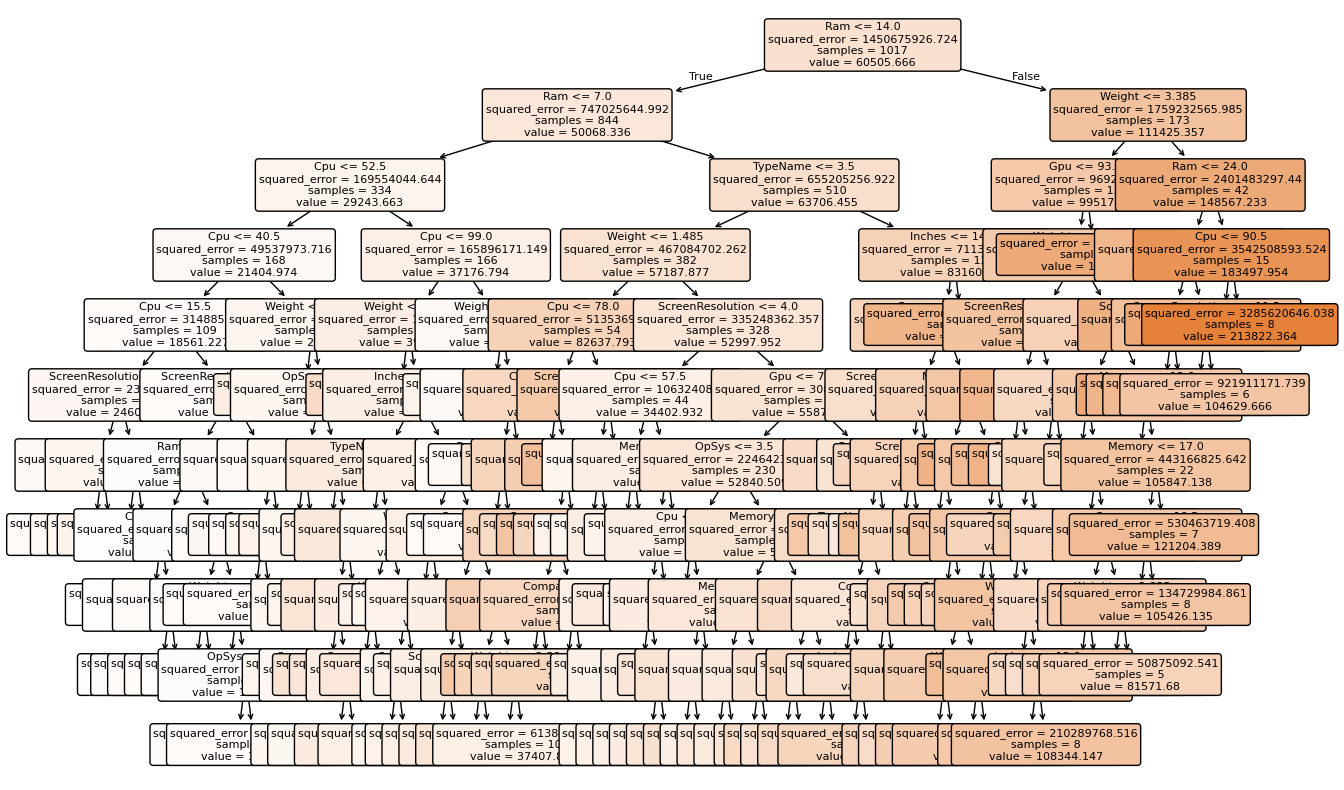

In [43]:
plt.figure(figsize=(15, 10))

plot_tree(
    model,
    feature_names = X_train.columns.tolist(),
    filled= True ,
    rounded= True ,
    fontsize= 8
)

plt.show()